# Data Cleaning and Exploratory Data Analysis

## Purpose

This notebook focuses on improving dataset quality and understanding patterns
within the natural fibre composite dataset.

The cleaning process addresses:

- Missing values
- Duplicate records
- Invalid measurements

Exploratory Data Analysis (EDA) is performed to investigate relationships
between material characteristics and mechanical properties.

In [1]:
# Data manipulation

import pandas as pd
import numpy as np


# Visualisation

import matplotlib.pyplot as plt


# Statistical visualization

import seaborn as sns

## Loading Dataset

The dataset from Notebook 01 is loaded again.
The cleaning process begins from the original dataset.

In [2]:
df = pd.read_csv("../data/raw/dataset_topic.csv")

df.head()

,fiber_type,matrix_type,fiber_configuration,orientation,num_plies,fiber_volume_fraction,elastic_modulus_mpa,tensile_strength_mpa,data_source
0,Flax,Epoxy,0,0 UD,3.0,0.3,20042.2367,297.4065,"Torres et al. (2017), Data in Brief, Vol.12, p..."
1,Flax,Epoxy,0,0 UD,3.0,0.3,19701.1091,289.9346,"Torres et al. (2017), Data in Brief, Vol.12, p..."
2,Flax,Epoxy,0,0 UD,3.0,0.3,17559.1106,274.8862,"Torres et al. (2017), Data in Brief, Vol.12, p..."
3,Flax,Epoxy,0,0 UD,3.0,0.3,19737.9379,277.5509,"Torres et al. (2017), Data in Brief, Vol.12, p..."
4,Flax,Epoxy,0,0 UD,3.0,0.3,18048.3804,286.1064,"Torres et al. (2017), Data in Brief, Vol.12, p..."


In [3]:
df.shape

(624, 9)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 624 entries, 0 to 623
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   fiber_type             624 non-null    str    
 1   matrix_type            612 non-null    str    
 2   fiber_configuration    624 non-null    str    
 3   orientation            624 non-null    str    
 4   num_plies              581 non-null    float64
 5   fiber_volume_fraction  600 non-null    float64
 6   elastic_modulus_mpa    598 non-null    float64
 7   tensile_strength_mpa   624 non-null    float64
 8   data_source            624 non-null    str    
dtypes: float64(4), str(5)
memory usage: 44.0 KB


# Part A - Data Cleaning

## Missing Values

Missing values are investigated before making cleaning decisions.

The aim is to understand which variables require treatment and which missing
values should be retained for prediction.

In [5]:
missing = df.isnull().sum()

missing[missing > 0]

matrix_type              12
num_plies                43
fiber_volume_fraction    24
elastic_modulus_mpa      26
dtype: int64

In [6]:
df = df.dropna(subset=[
    "matrix_type",
    "num_plies",
    "fiber_volume_fraction",
    "elastic_modulus_mpa"
])

df.drop(columns="data_source",inplace=True)

In [7]:
df.head()

,fiber_type,matrix_type,fiber_configuration,orientation,num_plies,fiber_volume_fraction,elastic_modulus_mpa,tensile_strength_mpa
0,Flax,Epoxy,0,0 UD,3.0,0.3,20042.2367,297.4065
1,Flax,Epoxy,0,0 UD,3.0,0.3,19701.1091,289.9346
2,Flax,Epoxy,0,0 UD,3.0,0.3,17559.1106,274.8862
3,Flax,Epoxy,0,0 UD,3.0,0.3,19737.9379,277.5509
4,Flax,Epoxy,0,0 UD,3.0,0.3,18048.3804,286.1064


In [9]:
df.isnull().sum()

fiber_type               0
matrix_type              0
fiber_configuration      0
orientation              0
num_plies                0
fiber_volume_fraction    0
elastic_modulus_mpa      0
tensile_strength_mpa     0
dtype: int64

## Duplicate Records

Duplicate observations can affect machine learning performance because the
model may learn repeated examples rather than general patterns.

In [10]:
df.duplicated().sum()

np.int64(0)

## Invalid Data Checking

Physical properties must fall within realistic engineering ranges.

Examples of invalid values:

- Negative tensile strength
- Negative elastic modulus
- Fibre volume fraction above 100%

In [11]:
df[df["tensile_strength_mpa"] < 0]

,fiber_type,matrix_type,fiber_configuration,orientation,num_plies,fiber_volume_fraction,elastic_modulus_mpa,tensile_strength_mpa


In [12]:
df[df.elastic_modulus_mpa < 0]

,fiber_type,matrix_type,fiber_configuration,orientation,num_plies,fiber_volume_fraction,elastic_modulus_mpa,tensile_strength_mpa


In [13]:
df[df["fiber_volume_fraction"] > 100]

,fiber_type,matrix_type,fiber_configuration,orientation,num_plies,fiber_volume_fraction,elastic_modulus_mpa,tensile_strength_mpa


In [14]:
df_cleaned = df.copy()

df_cleaned.to_csv(
    "../data/cleaned/cleaned_dataset.csv",
    index=False
)

df.shape

(581, 8)

# Part B — Exploratory Data Analysis

Now we investigate the behaviour of the material data.

In [15]:
df_cleaned.describe()

,num_plies,fiber_volume_fraction,elastic_modulus_mpa,tensile_strength_mpa
count,581.000000,581.000000,581.000000,581.000000
mean,3.721170,0.347349,7893.687512,107.574907
std,0.673168,0.054563,4166.518936,77.776426
min,1.000000,0.000000,43.900000,9.800000
25%,4.000000,0.310000,5812.140900,61.609200
50%,4.000000,0.350000,6803.351800,83.792900
75%,4.000000,0.400000,8610.095600,140.058600
max,4.000000,0.550000,20551.130300,316.848400


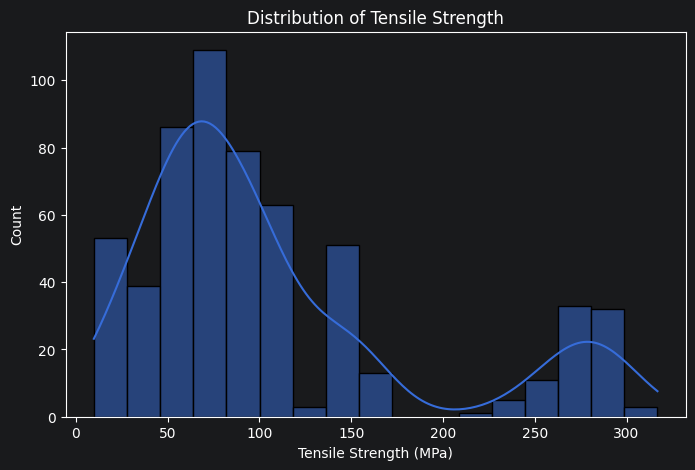

In [16]:
plt.figure(figsize=(8,5))

sns.histplot(
    df_cleaned["tensile_strength_mpa"],
    kde=True
)

plt.title("Distribution of Tensile Strength")

plt.xlabel("Tensile Strength (MPa)")

plt.show()

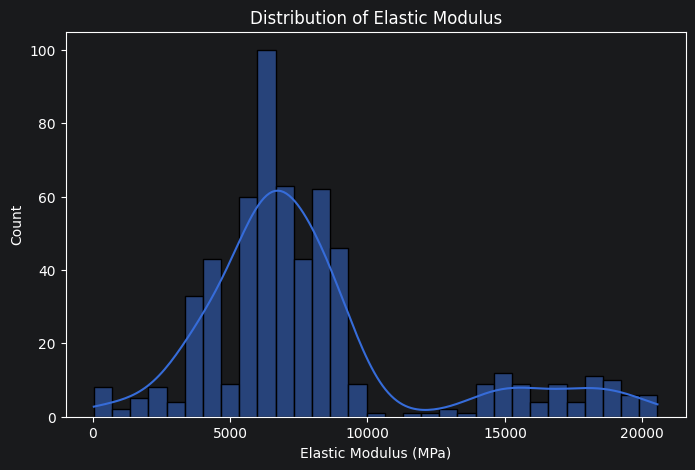

In [17]:
plt.figure(figsize=(8,5))

sns.histplot(
    df_cleaned["elastic_modulus_mpa"],
    kde=True
)

plt.title("Distribution of Elastic Modulus")

plt.xlabel("Elastic Modulus (MPa)")

plt.show()

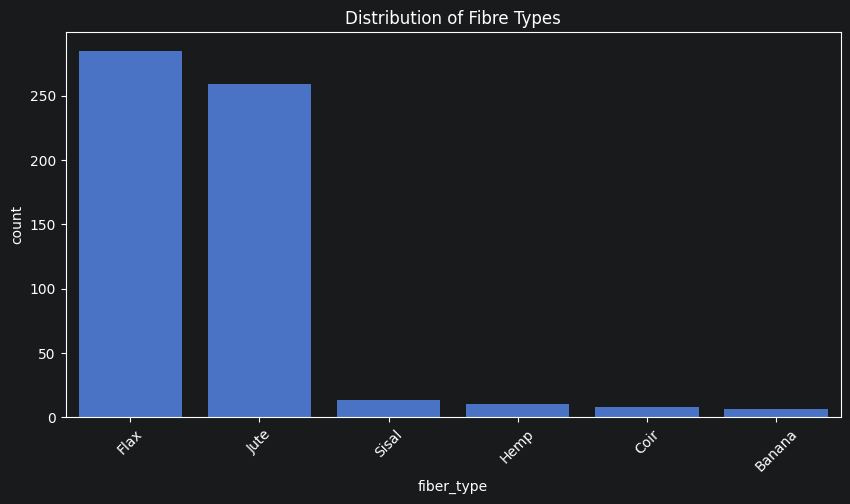

In [18]:
plt.figure(figsize=(10,5))

sns.countplot(
    data=df_cleaned,
    x="fiber_type"
)

plt.xticks(rotation=45)

plt.title("Distribution of Fibre Types")

plt.show()

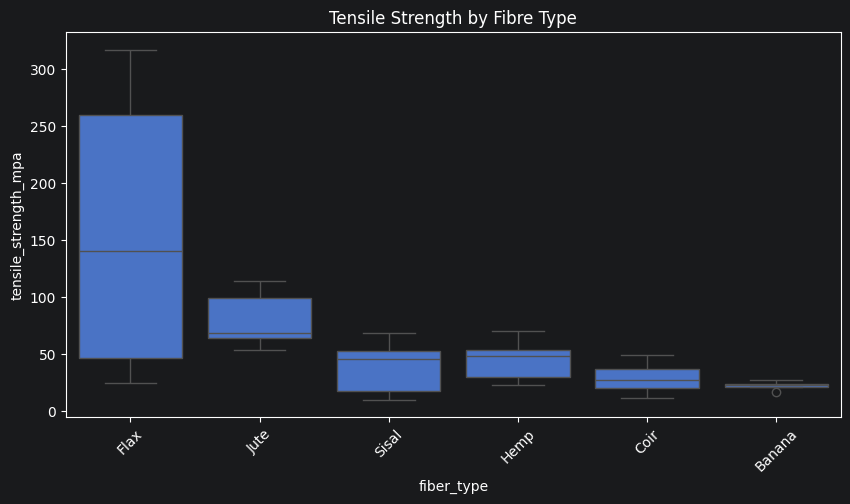

In [19]:
plt.figure(figsize=(10,5))

sns.boxplot(
    data=df_cleaned,
    x="fiber_type",
    y="tensile_strength_mpa"
)

plt.xticks(rotation=45)

plt.title("Tensile Strength by Fibre Type")

plt.show()

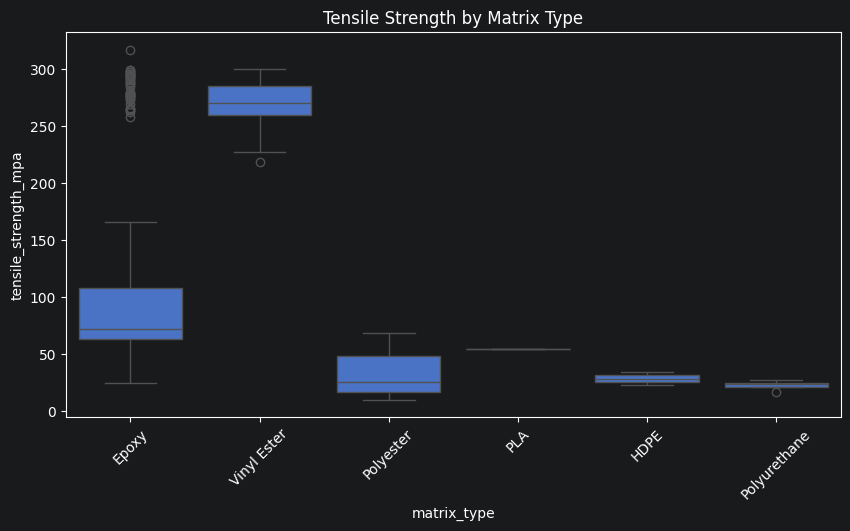

In [20]:
plt.figure(figsize=(10,5))

sns.boxplot(
    data=df_cleaned,
    x="matrix_type",
    y="tensile_strength_mpa"
)

plt.xticks(rotation=45)

plt.title("Tensile Strength by Matrix Type")

plt.show()

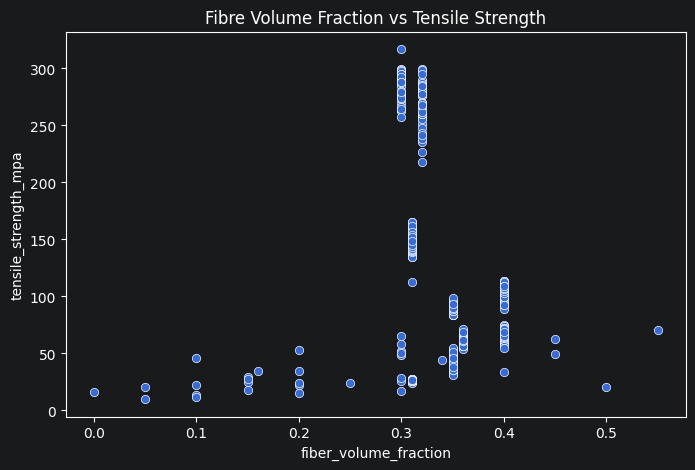

In [21]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df_cleaned,
    x="fiber_volume_fraction",
    y="tensile_strength_mpa"
)

plt.title(
    "Fibre Volume Fraction vs Tensile Strength"
)

plt.show()

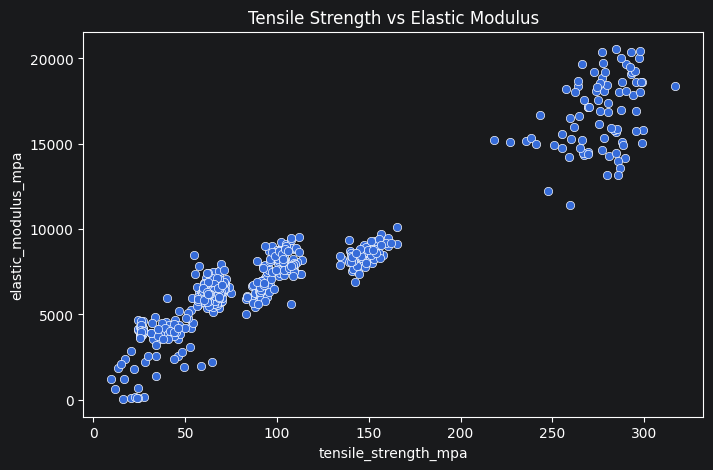

In [22]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df_cleaned,
    x="tensile_strength_mpa",
    y="elastic_modulus_mpa"
)

plt.title(
    "Tensile Strength vs Elastic Modulus"
)

plt.show()

In [23]:
numeric_df = df_cleaned.select_dtypes(
    include=np.number
)

correlation = numeric_df.corr()

correlation

,num_plies,fiber_volume_fraction,elastic_modulus_mpa,tensile_strength_mpa
num_plies,1.000000,0.629507,-0.182667,-0.271674
fiber_volume_fraction,0.629507,1.000000,-0.064600,-0.197721
elastic_modulus_mpa,-0.182667,-0.064600,1.000000,0.953661
tensile_strength_mpa,-0.271674,-0.197721,0.953661,1.000000


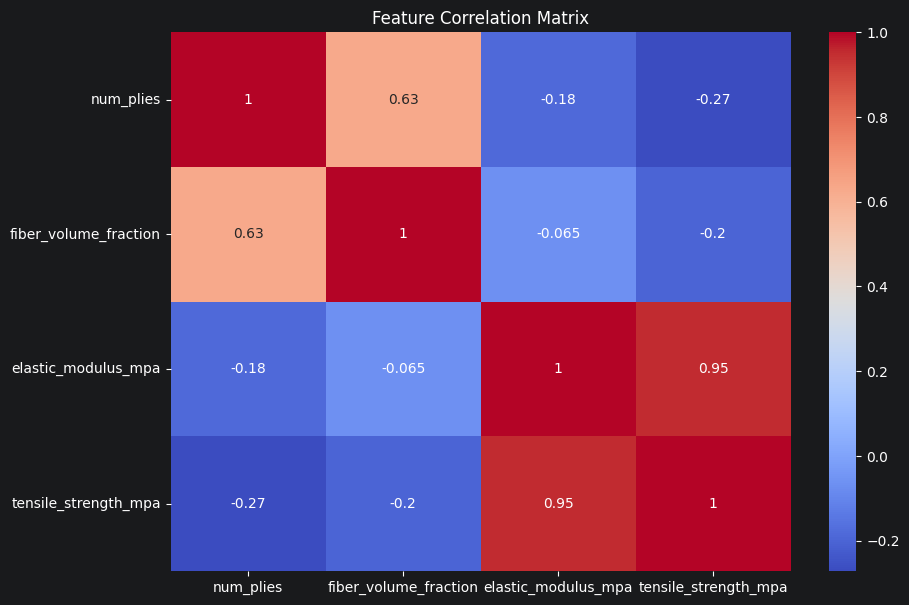

In [24]:
plt.figure(figsize=(10,7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm"
)

plt.title("Feature Correlation Matrix")

plt.show()

# EDA Summary

The dataset was cleaned by removing incomplete records for essential input
features and eliminating duplicate observations.

Exploratory analysis showed relationships between composite design parameters
and mechanical properties.

Important observations include:

- Fiber type influences mechanical performance.
- Fiber volume fraction affects tensile strength.
- Material variables show different levels of correlation with target properties.

The cleaned dataset will be used for feature engineering and machine learning
development.